# Labelbox Annotation Summary — STEPS-Paper-Annotation

Summarizes the Labelbox NDJSON export using the same detector-object rules as
Step 03. Plot/Diagram boxes with at least 85% of their area inside a mixed-figure
box are excluded; the outer mixed figure is retained. Objects without bounding
boxes are skipped. Both notebooks select the first label for each project/page.

All object counts and the saved summary CSV use these filtered objects.


In [1]:
# Locate the project from either the project root or a notebook directory.
import os
import sys
from pathlib import Path
PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / "Pre-Pages-2Annotate").is_dir())
sys.path.insert(0, str(PROJECT_ROOT / "My_code"))
from annotation_inputs import latest_annotation_export, annotated_image_paths, build_image_index
os.chdir(PROJECT_ROOT / 'My_code/step02_annotations_summary')
import json
from pathlib import Path
from collections import Counter, defaultdict

import pandas as pd
import matplotlib.pyplot as plt

ANNOTATIONS_ROOT = PROJECT_ROOT / "Pre-Pages-2Annotate" / "Exported_annotated_data"
EXPORT_PATH = latest_annotation_export(ANNOTATIONS_ROOT)
print(f"Annotation export: {EXPORT_PATH.name}")
MANIFEST_PATH = Path("..") / ".." / "Pre-Pages-2Annotate" / "manifest.csv"

assert EXPORT_PATH.exists(), f"Export not found at {EXPORT_PATH.resolve()}"

# Reuse Step 03's detector classification and nested-panel rules.
sys.path.insert(0, str(PROJECT_ROOT / "My_code/step03_labelbox_export"))
from step03_labelbox_export_to_dataset import effective_class, resolve_composites
CONTAINMENT_THRESHOLD = 0.85  # same default as Step 03


Annotation export: Export  project - STEPS-Paper-Annotation - 9_23_2026.ndjson


## Load and flatten the export

Each line of the NDJSON is one Labelbox data row (one page image). `select_label` picks which label to use when a data row has more than one (Labelbox consensus workflows can attach several independent labels per row) — this project's `consensus_expected_label_count` is 3, so we default to the first label, matching a single-source-of-truth read.

In [2]:
def flatten_classifications(classifications):
    """Turn Labelbox's nested classification structure into ['Name:answer', ...]."""
    out = []
    for c in classifications or []:
        cname = c.get("name", "")
        for ans in c.get("checklist_answers", []):
            out.append(f"{cname}:{ans.get('value', '')}")
            out.extend(flatten_classifications(ans.get("classifications", [])))
        if isinstance(c.get("answer"), dict):
            ans = c["answer"]
            out.append(f"{cname}:{ans.get('value', '')}")
            out.extend(flatten_classifications(ans.get("classifications", [])))
    return out


def select_label(labels, mode="first"):
    if not labels:
        return None
    return labels[0] if mode == "first" else labels  # mode="all" handled by caller if ever needed


pages = []          # one row per data_row (page)
objects_flat = []   # one row per detector object (nested panels excluded)
nested_excluded_count = 0

with open(EXPORT_PATH) as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        row = json.loads(line)
        external_id = row.get("data_row", {}).get("external_id", "")

        page_objects, page_no_graphics_flag, label_found = [], False, False

        for project_id, project in row.get("projects", {}).items():
            label = select_label(project.get("labels", []), mode="first")
            if label is None:
                continue
            label_found = True
            ann = label.get("annotations", {})
            label_objects = []
            for obj in ann.get("objects", []):
                bbox = obj.get("bounding_box")
                if not bbox:
                    continue  # match Step 03: only objects with bounding boxes
                subtypes = flatten_classifications(obj.get("classifications", []))
                label_objects.append({
                    "obj": obj,
                    "bbox": bbox,
                    "class_name": effective_class(obj.get("name", "unlabeled"), subtypes, True),
                })
            resolve_composites(label_objects, CONTAINMENT_THRESHOLD)
            nested_excluded_count += sum(o["nested_child_of_mixed"] for o in label_objects)
            page_objects.extend(
                o["obj"] for o in label_objects if not o["nested_child_of_mixed"]
            )

            for c in ann.get("classifications", []):
                for ans in c.get("checklist_answers", []):
                    if ans.get("value") == "no_graphics":
                        page_no_graphics_flag = True

        if not label_found:
            continue

        pages.append({
            "image": external_id,
            "has_label": label_found,
            "n_objects": len(page_objects),
            "explicit_no_graphics": page_no_graphics_flag,
        })

        for obj in page_objects:
            objects_flat.append({
                "image": external_id,
                "class": obj.get("name", "unlabeled"),
                "subtypes": ";".join(flatten_classifications(obj.get("classifications", []))),
                "feature_id": obj.get("feature_id", ""),
            })

df_pages = pd.DataFrame(pages, columns=["image", "has_label", "n_objects", "explicit_no_graphics"])
df_objects = pd.DataFrame(objects_flat, columns=["image", "class", "subtypes", "feature_id"])

print(f"Pages in export:   {len(df_pages)}")
print(f"Detector objects: {len(df_objects)}")
print(f"Nested Plot/Diagram boxes excluded: {nested_excluded_count}")
df_pages.head()


Pages in export:   267
Detector objects: 215
Nested Plot/Diagram boxes excluded: 11


,image,has_label,n_objects,explicit_no_graphics
0,Additives-for-reducing-nitrogen-loss-during-co...,True,0,True
1,Additives-for-reducing-nitrogen-loss-during-co...,True,1,False
2,Additives-for-reducing-nitrogen-loss-during-co...,True,1,False
3,Additives-for-reducing-nitrogen-loss-during-co...,True,1,False
4,Additives-for-reducing-nitrogen-loss-during-co...,True,2,False


## Pages with graphics vs. no graphics

This matches the original notebook's definition exactly: a page counts as "no graphics" whenever it has zero annotated objects — whether the labeler explicitly checked **No Graphics**, or submitted an empty label without checking anything. The breakdown just below splits those two cases apart, since they mean different things for QA.

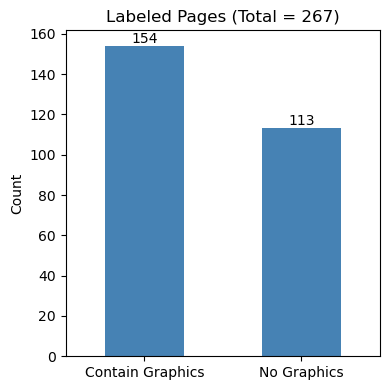

In [3]:
count_total = len(df_pages)
count_graphics = int((df_pages["n_objects"] > 0).sum())
count_no_graphics = count_total - count_graphics

counts_total = {"Contain Graphics": count_graphics, "No Graphics": count_no_graphics}

ax = pd.Series(counts_total).sort_values(ascending=False).plot(
    kind="bar", figsize=(4, 4), color="steelblue"
)
ax.bar_label(ax.containers[0])
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.title(f"Labeled Pages (Total = {count_total})")
plt.tight_layout()
plt.show()


In [4]:
# Diagnostic: within "No Graphics", how many were explicitly marked vs. left blank?
explicit_no_graphics = int(((df_pages["n_objects"] == 0) & df_pages["explicit_no_graphics"]).sum())
conflicting_flags = int(((df_pages["n_objects"] > 0) & df_pages["explicit_no_graphics"]).sum())
print(f"Pages with objects AND a No Graphics flag (review): {conflicting_flags}")
blank_submissions = count_no_graphics - explicit_no_graphics

print(f"No Graphics (explicitly checked):  {explicit_no_graphics}")
print(f"No Graphics (blank / unchecked):    {blank_submissions}")
if blank_submissions:
    print(
        f"\n{blank_submissions} page(s) were submitted with neither an object "
        f"nor the 'No Graphics' checkbox — worth a second look before treating "
        f"them as confirmed blank pages."
    )


Pages with objects AND a No Graphics flag (review): 1
No Graphics (explicitly checked):  113
No Graphics (blank / unchecked):    0


## Object type counts (Figure / Table / ...)

Counts detector objects after excluding nested Plot/Diagram panels, matching Step 03.


{'Figure': 144, 'Table': 71}


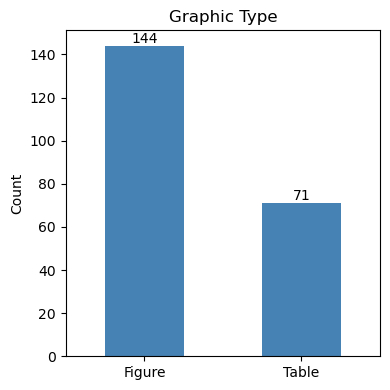

In [5]:
counts_graphics = df_objects["class"].value_counts().to_dict()
print(counts_graphics)

if counts_graphics:
    ax = pd.Series(counts_graphics).sort_values(ascending=False).plot(
        kind="bar", figsize=(4, 4), color="steelblue"
    )
    ax.bar_label(ax.containers[0])
    plt.ylabel("Count")
    plt.title("Graphic Type")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
else:
    print("No entries to plot.")


## Figure type counts (plot / diagram / mixed_figure)

Each retained Figure is counted exactly once; nested Plot/Diagram panels are excluded. Figures annotated with both plot and diagram
(including plot + diagram + table) are grouped as mixed_figure. Standalone Table
objects are counted separately in the Graphic Type chart.


{'diagram': 57, 'plot': 71, 'mixed_figure': 16}


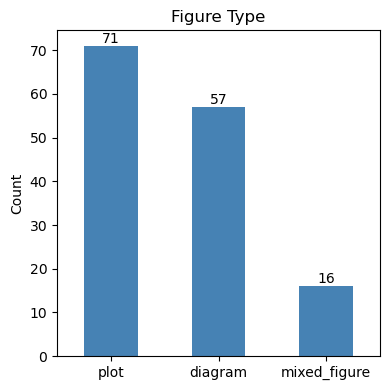

In [6]:
def figure_type(subtypes):
    """Assign one category per figure using its Type annotations."""
    answers = {
        tag.split(":", 1)[1].strip().lower()
        for tag in subtypes.split(";")
        if tag.startswith("Type:")
    }
    if "mixed_figure" in answers or {"plot", "diagram"}.issubset(answers):
        return "mixed_figure"
    if answers == {"plot"}:
        return "plot"
    if answers == {"diagram"}:
        return "diagram"
    raise ValueError(f"Unexpected figure subtype combination: {subtypes!r}")


subtype_counter = Counter(
    figure_type(subtypes)
    for subtypes in df_objects.loc[df_objects["class"] == "Figure", "subtypes"]
)

counts_figure = dict(subtype_counter)
print(counts_figure)

if counts_figure:
    ax = pd.Series(counts_figure).sort_values(ascending=False).plot(
        kind="bar", figsize=(4, 4), color="steelblue"
    )
    ax.bar_label(ax.containers[0])
    plt.ylabel("Count")
    plt.title("Figure Type")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
else:
    print("No entries to plot.")


## Annotation progress by topic

Cross-references the flat object list against `manifest.csv` (topic → paper mapping) to show how much of each topic folder has been labeled so far.

In [7]:
# Derive topics from the actual image folders; no stale manifest required.
image_index = build_image_index(PROJECT_ROOT / "Pre-Pages-2Annotate")
def topic_for(image):
    path = image_index.get(image)
    return path.relative_to(PROJECT_ROOT / "Pre-Pages-2Annotate").parts[0] if path else "missing image"
df_pages["paper"] = df_pages["image"].str.rsplit("_page_", n=1).str[0]
df_pages["topic"] = df_pages["image"].apply(topic_for)
progress = df_pages.groupby("topic").agg(
    pages=("image", "count"),
    pages_with_graphics=("n_objects", lambda s: int((s > 0).sum())),
)
progress["pages_with_no_graphics"] = progress["pages"] - progress["pages_with_graphics"]
progress


,pages,pages_with_graphics,pages_with_no_graphics
topic,,,
Recovery,124,77,47
Recovery - Fertilizer,143,77,66


## Save the filtered object table

Save detector objects only, with the original Figure/Table class and subtype tags.
Unlike Step 03's full CSV, this summary CSV excludes nested Plot/Diagram panels.


In [8]:
OUTPUT_CSV = Path("annotations_flat.csv")
df_objects.to_csv(OUTPUT_CSV, index=False)
print(f"Saved {len(df_objects)} object rows to {OUTPUT_CSV.resolve()}")


Saved 215 object rows to /Users/md_halim_mondol/Desktop/STEPS-LLM/2026/My_code/step02_annotations_summary/annotations_flat.csv
